# Exploratory data analysis: Online Retail II

A short look at the data behind the recommender, read straight from the SQLite tables built by
`python -m src.run_all --stage data`. Five questions:

1. What does cleaning remove?
2. How skewed is item popularity?
3. How much history do customers have (who is "cold")?
4. Where do the split boundaries fall, and is demand seasonal?
5. Do the description-derived product categories make sense?

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import config
from src.models import build_item_embeddings
from src.split import chronological_split
from src.sql import connect, query_frame

BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "axes.titlelocation": "left"})
conn = connect()

## 1. What cleaning removes

In [2]:
report = query_frame(conn, "06_cleaning_report.sql").iloc[0]
rules = report[["null_customer", "cancelled_invoice", "non_positive_quantity",
                "non_positive_price", "non_product_code"]]
print(f"raw rows:   {report['raw_rows']:>9,}")
for rule, n in rules.items():
    print(f"  {rule:<22} {n:>9,}  ({n / report['raw_rows']:.1%} of raw rows)")
print(f"clean rows: {report['clean_rows']:>9,}  ({report['clean_rows'] / report['raw_rows']:.1%} kept)")
print(f"customers {report['customers']:,} | products {report['products']:,} | "
      f"invoices {report['invoices']:,} | user-item interactions {report['interactions']:,}")

raw rows:   1,067,371
  null_customer            243,007  (22.8% of raw rows)
  cancelled_invoice         19,494  (1.8% of raw rows)
  non_positive_quantity     22,950  (2.2% of raw rows)
  non_positive_price         6,207  (0.6% of raw rows)
  non_product_code           6,093  (0.6% of raw rows)
clean rows:   776,577  (72.8% kept)
customers 5,852 | products 4,619 | invoices 36,594 | user-item interactions 480,971


Rules overlap (a cancelled invoice also has negative quantities), so the counts do not sum to the
number of dropped rows. Anonymous checkouts are by far the largest loss: without a customer id
there is nobody to build a history for.

## 2. Item popularity is heavy-tailed

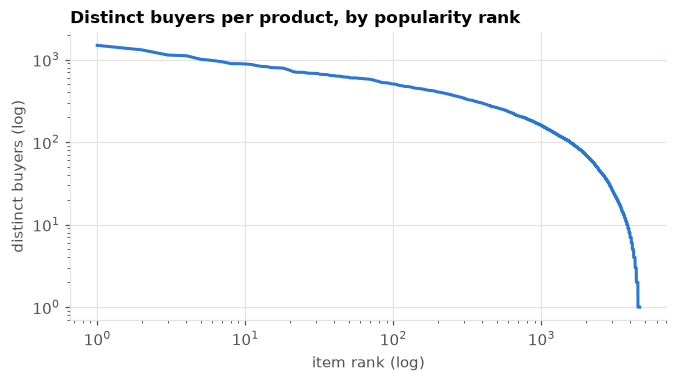

top   1% of products (  46) account for 7.5% of interactions
top  10% of products ( 461) account for 41.0% of interactions
top  20% of products ( 923) account for 61.7% of interactions
interaction matrix density: 1.78%


,stock_code,description,n_customers
0,85123A,WHITE HANGING HEART T-LIGHT HOLDER,1490
1,22423,REGENCY CAKESTAND 3 TIER,1314
2,22138,BAKING SET 9 PIECE RETROSPOT,1137
3,21212,PACK OF 72 RETROSPOT CAKE CASES,1115
4,84879,ASSORTED COLOUR BIRD ORNAMENT,1010


In [3]:
items = pd.read_sql_query("SELECT * FROM items ORDER BY n_customers DESC", conn)
interactions = pd.read_sql_query("SELECT * FROM interactions", conn)
share = items["n_customers"].cumsum() / items["n_customers"].sum()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(np.arange(1, len(items) + 1), items["n_customers"], color=BLUE, linewidth=2)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("item rank (log)"); ax.set_ylabel("distinct buyers (log)")
ax.set_title("Distinct buyers per product, by popularity rank")
ax.grid(color=GRID, linewidth=0.8)
plt.show()

for pct in (0.01, 0.10, 0.20):
    n = int(len(items) * pct)
    print(f"top {pct:>4.0%} of products ({n:>4}) account for {share.iloc[n - 1]:.1%} of interactions")
density = len(interactions) / (interactions["customer_id"].nunique() * len(items))
print(f"interaction matrix density: {density:.2%}")
items.head(5)[["stock_code", "description", "n_customers"]]

A small head of best-sellers dominates, which is why a popularity recommender is a real baseline
here, and why catalogue coverage is reported next to accuracy.

## 3. How much history do customers have?

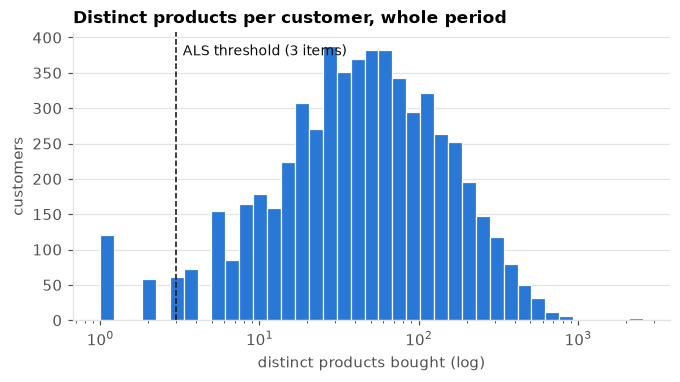

count    5852.0
mean       82.2
std       116.5
min         1.0
10%         8.0
50%        45.0
90%       198.0
max      2546.0
customers with fewer than 3 distinct products: 180 (3.1%)


In [4]:
history = interactions.groupby("customer_id")["stock_code"].nunique()

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.hist(history, bins=np.logspace(0, np.log10(history.max()), 40), color=BLUE,
        edgecolor="#fcfcfb", linewidth=0.8)
ax.axvline(config.MIN_HISTORY, color=INK, linewidth=1, linestyle="--")
ax.text(config.MIN_HISTORY * 1.1, ax.get_ylim()[1] * 0.92, "ALS threshold (3 items)", color=INK,
        fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("distinct products bought (log)"); ax.set_ylabel("customers")
ax.set_title("Distinct products per customer, whole period")
ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.show()

print(history.describe(percentiles=[0.1, 0.5, 0.9]).round(1).to_string())
print(f"customers with fewer than {config.MIN_HISTORY} distinct products: "
      f"{(history < config.MIN_HISTORY).sum():,} ({(history < config.MIN_HISTORY).mean():.1%})")

Customers here are mostly small retailers buying dozens of lines per order, so very few
*existing* customers sit below the 3-item threshold. Cold-start in this data is mainly about
customers who have never been seen before the test window; the pipeline measures that share
directly instead of assuming it.

## 4. Split boundaries and seasonality

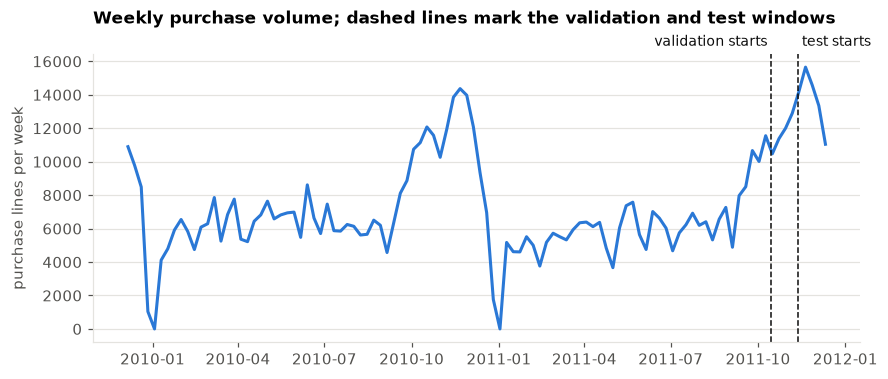

{'train_start': '2009-12-01 00:00:00', 'val_start': '2011-10-15 00:00:00', 'test_start': '2011-11-12 00:00:00', 'test_end': '2011-12-10 00:00:00'}
train  423,891 interactions  5,527 customers  4,544 products
val     44,885 interactions  1,414 customers  2,638 products
test    49,588 interactions  1,527 customers  2,629 products
test-window customers never seen before the test window: 133 of 1,527


In [5]:
split = chronological_split(conn)
weekly = pd.read_sql_query(
    "SELECT invoice_date, customer_id FROM clean_transactions", conn, parse_dates=["invoice_date"]
).set_index("invoice_date").resample("W")["customer_id"].size()

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(weekly.index, weekly.to_numpy(), color=BLUE, linewidth=2)
for name, start in (("validation", split.bounds.val_start), ("test", split.bounds.test_start)):
    ax.axvline(start, color=INK, linewidth=1, linestyle="--")
top = ax.get_ylim()[1] * 1.03
ax.text(split.bounds.val_start, top, "validation starts ", color=INK, fontsize=9, ha="right")
ax.text(split.bounds.test_start, top, " test starts", color=INK, fontsize=9, ha="left")
ax.set_ylabel("purchase lines per week")
ax.set_title("Weekly purchase volume; dashed lines mark the validation and test windows", pad=20)
ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
plt.show()

print(split.bounds.as_dict())
for name in ("train", "val", "test"):
    frame = getattr(split, name)
    print(f"{name:<5} {len(frame):>8,} interactions  {frame['customer_id'].nunique():>5,} customers  "
          f"{frame['stock_code'].nunique():>5,} products")
new_customers = set(split.test["customer_id"]) - set(split.train_val["customer_id"])
print(f"test-window customers never seen before the test window: {len(new_customers):,} of "
      f"{split.test['customer_id'].nunique():,}")

Volume climbs steeply every autumn into the Christmas peak, and both hold-out windows sit inside
that peak. Two consequences worth keeping in mind when reading the results: an all-time
popularity ranking is stale during the test window, and a popularity ranking restricted to
recent weeks is a much tougher reference.

## 5. Product categories derived from descriptions

In [6]:
descriptions = dict(zip(items["stock_code"], items["description"]))
catalogue = np.sort(items["stock_code"].to_numpy().astype(str))
embeddings = build_item_embeddings(catalogue, descriptions)
labelled = pd.DataFrame({"stock_code": catalogue, "category": embeddings.categories}).merge(
    items[["stock_code", "description", "n_customers"]], on="stock_code")

sizes = labelled["category"].value_counts()
print(f"{len(sizes)} KMeans categories; sizes from {sizes.min()} to {sizes.max()} products\n")
for category in sizes.index[1:7]:
    top = labelled[labelled["category"] == category].nlargest(4, "n_customers")["description"]
    print(f"category {category:>2} ({sizes[category]:>3} products): " + " | ".join(top))
conn.close()

40 KMeans categories; sizes from 43 to 496 products

category  6 (224 products): BAKING SET 9 PIECE RETROSPOT | SET OF 3 CAKE TINS PANTRY DESIGN | BAKING SET SPACEBOY DESIGN | JAM MAKING SET WITH JARS
category 31 (210 products): SCOTTIE DOG HOT WATER BOTTLE | HOME BUILDING BLOCK WORD | RETROSPOT HEART HOT WATER BOTTLE | CHOCOLATE HOT WATER BOTTLE
category 22 (148 products): SET/10 PINK POLKADOT PARTY CANDLES | PINK HAPPY BIRTHDAY BUNTING | PINK REGENCY TEACUP AND SAUCER | TOY TIDY PINK RETROSPOT
category  0 (144 products): ZINC WILLIE WINKIE  CANDLE STICK | CITRONELLA CANDLE FLOWERPOT | CITRONELLA CANDLE GARDEN POT | INFLATABLE POLITICAL GLOBE
category 35 (143 products): REX CASH+CARRY JUMBO SHOPPER | LUNCH BAG SPACEBOY DESIGN | LUNCH BAG  BLACK SKULL. | LUNCH BAG CARS BLUE
category 26 (139 products): NATURAL SLATE HEART CHALKBOARD | ZINC METAL HEART DECORATION | SET OF 3 HEART COOKIE CUTTERS | WOODEN HEART CHRISTMAS SCANDINAVIAN


The clusters are driven by shared words, so they mix true product families (lunch bags, hot
water bottles, candles) with themes (everything PINK, everything HEART). That is a limit of
embedding short descriptions, and it is the only item signal the content-based fallback has when
a customer has one or two purchases.